In [3]:
#import core libraries
import pandas as pd

In [5]:
# Load CSV from raw data folder
df = pd.read_csv(r"C:\Users\01\Downloads\HR_Attrition_Analytics_Project\HR_comma_sep.csv")
print(df.to_string())

       satisfaction_level  last_evaluation  number_project  average_montly_hours  time_spend_company  Work_accident  left  promotion_last_5years   Department  salary
0                    0.38             0.53               2                   157                   3              0     1                      0        sales     low
1                    0.80             0.86               5                   262                   6              0     1                      0        sales  medium
2                    0.11             0.88               7                   272                   4              0     1                      0        sales  medium
3                    0.72             0.87               5                   223                   5              0     1                      0        sales     low
4                    0.37             0.52               2                   159                   3              0     1                      0        sales     low
5   

In [8]:
# Preview data
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [10]:
# Shape of dataset
print("Rows, Columns:", df.shape)

# Info and data types
df.info()

# Basic statistical summary
df.describe()


Rows, Columns: (14999, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Department             14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


In [16]:
 #CLEANING DATA:Check for NULLs 
df.isnull().sum()


satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
Department               0
salary                   0
dtype: int64

In [20]:
#Remove duplicates (if any)
df.duplicated().sum()



0

In [23]:
df = df.drop_duplicates()

In [25]:
# 1. Find out overall Attrition Rate
attrition_rate = df['left'].mean() * 100
print(f"Overall Attrition Rate: {attrition_rate:.2f}%")


Overall Attrition Rate: 16.60%


In [37]:
# 2.Attrition by Department
dept_attrition = df.groupby('Department')['left'].mean().sort_values(ascending=False) * 100
print(dept_attrition)


Department
hr             18.801997
accounting     17.552335
technical      17.379679
support        17.133443
sales          16.980550
marketing      16.641902
IT             16.188525
product_mng    16.034985
RandD          12.247839
management     11.926606
Name: left, dtype: float64


In [39]:
print(df.columns)


Index(['satisfaction_level', 'last_evaluation', 'number_project',
       'average_montly_hours', 'time_spend_company', 'Work_accident', 'left',
       'promotion_last_5years', 'Department', 'salary'],
      dtype='object')


In [29]:
# 3.Satisfaction vs Attrition
df.groupby('left')['satisfaction_level'].mean()


left
0    0.667365
1    0.440271
Name: satisfaction_level, dtype: float64

In [41]:
# 4.Workload Analysis
df.groupby('left')[['average_montly_hours', 'number_project']].mean()


,average_montly_hours,number_project
left,,
0,198.94270,3.786800
1,208.16223,3.883476


In [33]:
# 5. Promotion Impact
df.groupby('promotion_last_5years')['left'].mean() * 100


promotion_last_5years
0    16.822192
1     3.940887
Name: left, dtype: float64

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


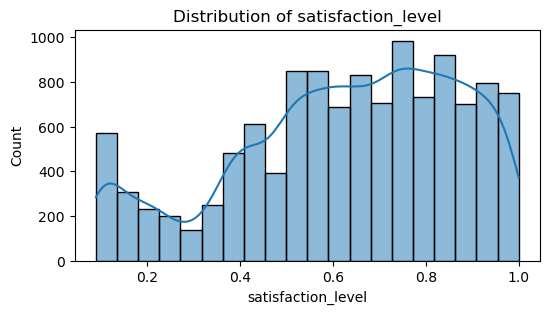

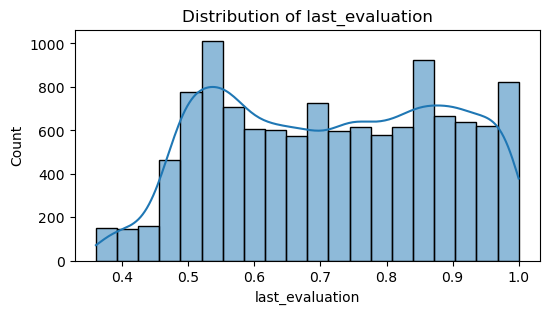

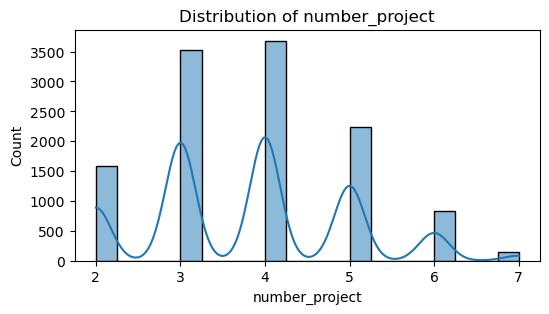

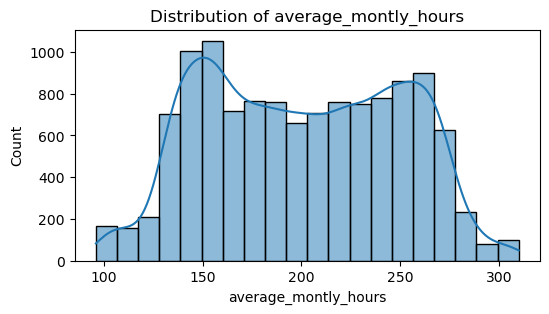

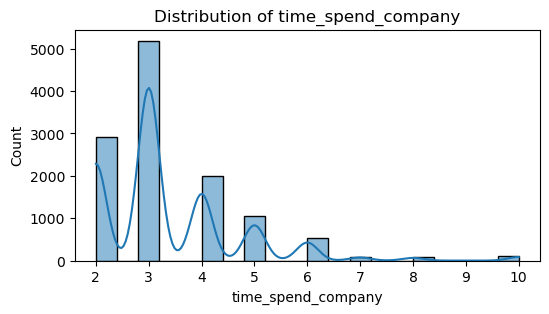

In [49]:
# Exploratory data analysis
# 1 Distributions of numeric features

numeric_cols = [
    "satisfaction_level", "last_evaluation", "number_project",
    "average_montly_hours", "time_spend_company"
]

for col in numeric_cols:
    plt.figure(figsize=(6,3))
    sns.histplot(df[col], kde=True, bins=20)
    plt.title(f'Distribution of {col}')
    plt.show()


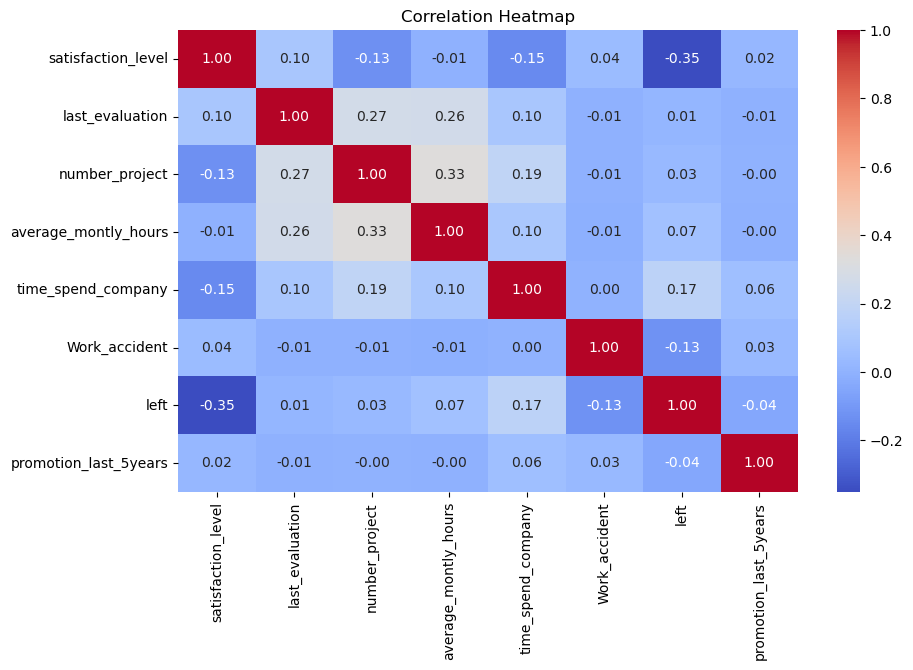

In [53]:
#2 .Correlation Heatmap
# Select numeric columns only
numeric_df = df.select_dtypes(include=['int64', 'float64'])

# Correlation heatmap
plt.figure(figsize=(10,6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()


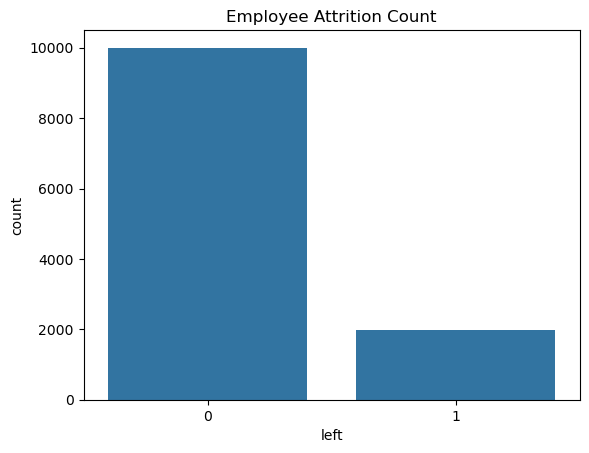

In [55]:
#3 .Attrition vs Features
#Attrition count
sns.countplot(data=df, x='left')
plt.title("Employee Attrition Count")
plt.show()


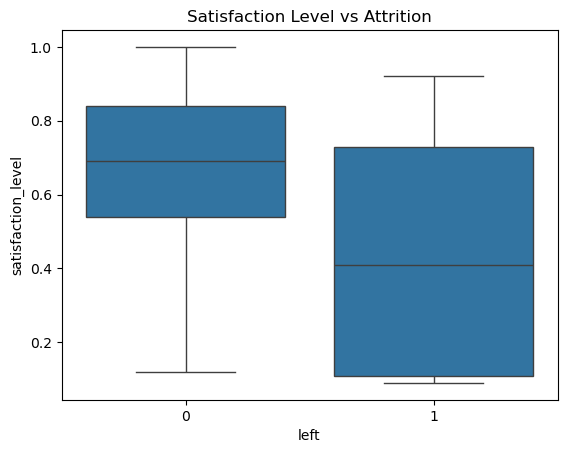

In [57]:
# Satisfaction vs Attrition
sns.boxplot(x='left', y='satisfaction_level', data=df)
plt.title("Satisfaction Level vs Attrition")
plt.show()

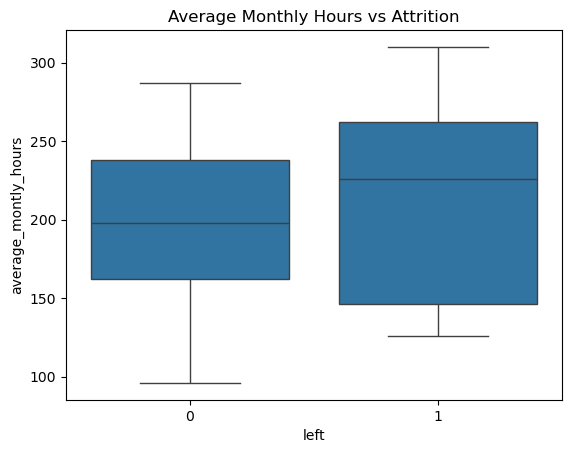

In [61]:
#Average Monthly Hours vs Attrition
sns.boxplot(x='left', y='average_montly_hours', data=df)
plt.title("Average Monthly Hours vs Attrition")
plt.show()



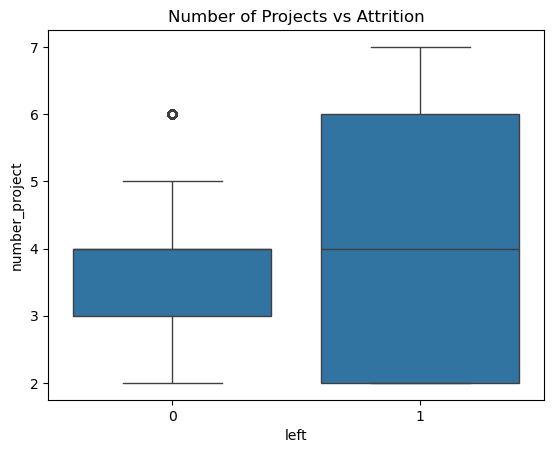

In [63]:
#Number of Projects vs Attrition
sns.boxplot(x='left', y='number_project', data=df)
plt.title("Number of Projects vs Attrition")
plt.show()

In [67]:
#Feature Creation 
#Example: High workload flag
df['high_workload'] = np.where(df['average_montly_hours'] > 200, 1, 0)
df[['average_montly_hours', 'high_workload']].head()


,average_montly_hours,high_workload
0,157,0
1,262,1
2,272,1
3,223,1
4,159,0


In [69]:
# Example: Low satisfaction flag
df['low_satisfaction'] = np.where(df['satisfaction_level'] < 0.5, 1, 0)
df[['satisfaction_level', 'low_satisfaction']].head()

,satisfaction_level,low_satisfaction
0,0.38,1
1,0.80,0
2,0.11,1
3,0.72,0
4,0.37,1


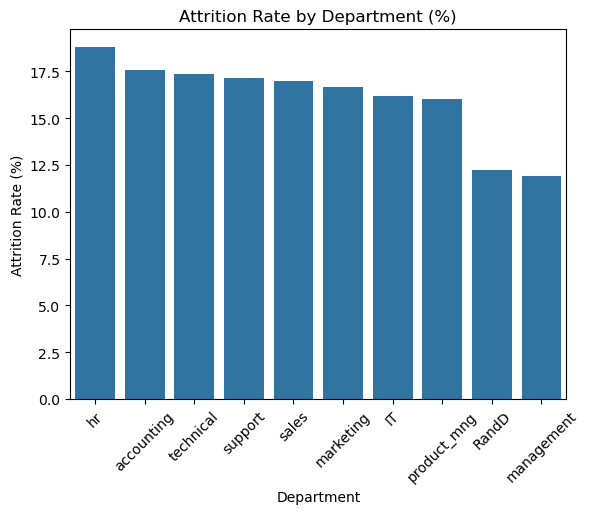

In [73]:
#Visual Explanations
#1 .Attrition by Department
dept_attrition = df.groupby('Department')['left'].mean().sort_values(ascending=False) * 100
sns.barplot(x=dept_attrition.index, y=dept_attrition.values)
plt.title("Attrition Rate by Department (%)")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=45)
plt.show()


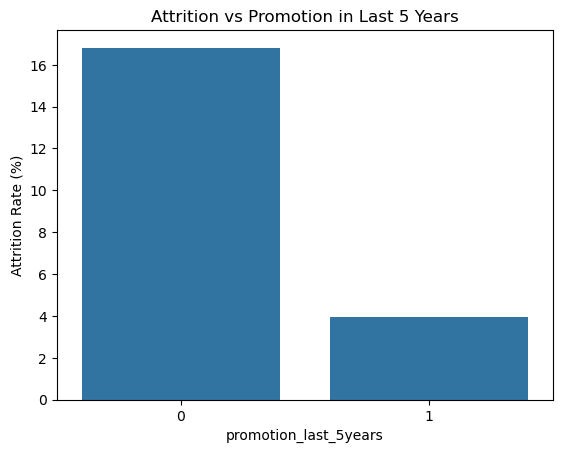

In [75]:
#Promotion Impact
promo_attrition = df.groupby('promotion_last_5years')['left'].mean() * 100
sns.barplot(x=promo_attrition.index, y=promo_attrition.values)
plt.title("Attrition vs Promotion in Last 5 Years")
plt.ylabel("Attrition Rate (%)")
plt.show()

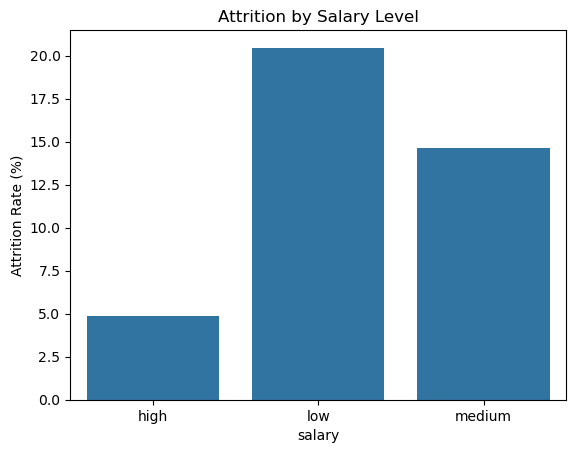

In [77]:
#Salary vs Attrition
salary_attrition = df.groupby('salary')['left'].mean() * 100
sns.barplot(x=salary_attrition.index, y=salary_attrition.values)
plt.title("Attrition by Salary Level")
plt.ylabel("Attrition Rate (%)")
plt.show()